# Fine-Tuning — Logistic Regression Head
Run **after** `finetune_neuralnet.ipynb` (it loads `finetune_shared.pt`).

Uses the *same* fine-tuned blocks as the neural-net notebook, then applies Logistic Regression on the extracted features. Evaluated three ways:
- **80/10/10** and **70/15/15** single splits (LR fit on train, tested on held-out)
- **5-fold CV** over all 148 subjects (out-of-fold predictions computed in the NN notebook's shared CV run)

Because it reuses the identical fine-tuned features, NN-head vs LR is a fair head-to-head comparison.

In [1]:
import os, sys, json, math
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix,
                             ConfusionMatrixDisplay, roc_curve, roc_auc_score)
import matplotlib.pyplot as plt
from tqdm import tqdm

sys.path.insert(0, '/Users/faenegoro/Documents/Neuroimaging/BrainOmni')
from brainomni.model import BrainOmni

device = torch.device('mps') if torch.backends.mps.is_available() else torch.device('cpu')
print('Device:', device)

W0708 12:25:08.136000 39035 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Device: mps


In [2]:
CKPT_PATH = '/Users/faenegoro/Documents/Neuroimaging/BrainOmni/ckpt_collection/tiny'
SAVE_DIR  = '../data/preprocessed'
OUT_DIR   = '../results/figures'
os.makedirs(OUT_DIR, exist_ok=True)

with open(os.path.join(CKPT_PATH, 'model_cfg.json')) as f:
    model_config = json.load(f)
base_checkpoint = torch.load(
    os.path.join(CKPT_PATH, 'BrainOmni.pt'), map_location='cpu', weights_only=True
)

proj_out1 = np.load(os.path.join(SAVE_DIR, 'proj_out1.npy'))  # (N, 16, NT, 256) tokenizer output
proj_out2 = np.load(os.path.join(SAVE_DIR, 'proj_out2.npy'))
labels    = np.load(os.path.join(SAVE_DIR, 'labels.npy'))
N = len(labels)

# Baselines (5-fold CV) from evaluation.ipynb
FROZEN_CV    = 0.831
HANDCRAFT_CV = 0.872

def make_split(labels, holdout, seed=123):
    """Stratified split. holdout=0.10 -> 80/10/10; holdout=0.15 -> 70/15/15."""
    idx = np.arange(len(labels))
    tr, tmp = train_test_split(idx, test_size=2 * holdout, stratify=labels, random_state=seed)
    va, te  = train_test_split(tmp, test_size=0.5, stratify=labels[tmp], random_state=seed)
    return tr, va, te

SPLITS = {'80/10/10': make_split(labels, 0.10),
          '70/15/15': make_split(labels, 0.15)}
for name, (tr, va, te) in SPLITS.items():
    print(f'{name}: train {len(tr)} | val {len(va)} | test {len(te)}')

shared = torch.load(os.path.join(SAVE_DIR, 'finetune_shared.pt'), weights_only=False)
nn_split_saved = shared['nn_split']   # fine-tuned block weights per split/config
cv_results     = shared['cv']         # CV out-of-fold predictions (incl. LR head)
print('Loaded finetune_shared.pt from the neural-net notebook.')

80/10/10: train 118 | val 15 | test 15
70/15/15: train 103 | val 22 | test 23
Loaded finetune_shared.pt from the neural-net notebook.


In [3]:
class CachedMEGDataset(Dataset):
    def __init__(self, indices, cached1, cached2, labels):
        self.indices, self.cached1, self.cached2, self.labels = indices, cached1, cached2, labels
    def __len__(self): return len(self.indices)
    def __getitem__(self, i):
        idx = self.indices[i]
        return self.cached1[idx], self.cached2[idx], torch.tensor(self.labels[idx], dtype=torch.long)

class FinetuneClassifier(nn.Module):
    def __init__(self, encoder_blocks, hidden_dim=256):
        super().__init__()
        self.blocks = encoder_blocks
        self.head = nn.Sequential(
            nn.Linear(hidden_dim * 16, 128), nn.ReLU(), nn.Dropout(0.3), nn.Linear(128, 2))
    def forward(self, x1, x2):
        x1, x2 = x1.to(device), x2.to(device)
        for block in self.blocks:
            x1 = block(x1); x2 = block(x2)
        x1 = F.normalize(x1, p=2.0, dim=-1, eps=1e-6).mean(dim=2)
        x2 = F.normalize(x2, p=2.0, dim=-1, eps=1e-6).mean(dim=2)
        return self.head(((x1 + x2) / 2).flatten(1))

def make_warmup_cosine(optimizer, total_steps, warmup_ratio=0.1, warmup_min=0.1, cos_min=0.1):
    warmup_steps = max(1, int(total_steps * warmup_ratio))
    def lr_lambda(step):
        if step < warmup_steps:
            return warmup_min + (1 - warmup_min) * step / warmup_steps
        prog = (step - warmup_steps) / max(1, total_steps - warmup_steps)
        return cos_min + (1 - cos_min) * 0.5 * (1 + math.cos(math.pi * prog))
    return torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)

def fresh_frozen_model():
    m = BrainOmni(**model_config)
    m.load_state_dict(base_checkpoint, strict=False)
    for p in m.parameters():
        p.requires_grad = False
    return m.to(device).eval()

def cache_frozen(model, n_frozen):
    """Run every subject through frozen blocks 0..n_frozen-1 (tokenizer output is proj_out)."""
    c1, c2 = [], []
    with torch.no_grad():
        for i in range(N):
            x1 = torch.tensor(proj_out1[i]).unsqueeze(0).to(device)
            x2 = torch.tensor(proj_out2[i]).unsqueeze(0).to(device)
            for block in list(model.blocks)[:n_frozen]:
                x1 = block(x1); x2 = block(x2)
            c1.append(x1.squeeze(0).cpu()); c2.append(x2.squeeze(0).cpu())
    return c1, c2

def extract_features(model, ft_blocks, n_frozen):
    """Every subject through frozen + fine-tuned blocks -> (N, 4096) features (for LR)."""
    feats = []
    with torch.no_grad():
        for i in range(N):
            x1 = torch.tensor(proj_out1[i]).unsqueeze(0).to(device)
            x2 = torch.tensor(proj_out2[i]).unsqueeze(0).to(device)
            for block in list(model.blocks)[:n_frozen]:
                x1 = block(x1); x2 = block(x2)
            for block in ft_blocks:
                x1 = block(x1); x2 = block(x2)
            x1 = F.normalize(x1, p=2.0, dim=-1, eps=1e-6).mean(dim=2).flatten(1)
            x2 = F.normalize(x2, p=2.0, dim=-1, eps=1e-6).mean(dim=2).flatten(1)
            feats.append(((x1 + x2) / 2).squeeze(0).cpu().numpy())
    return np.array(feats)

BACKBONE_LR, HEAD_LR = 1e-5, 1e-4  # official recipe: pretrained backbone small, random head 10x

print('Model helpers ready.')

Model helpers ready.


## Logistic Regression on the two single splits

In [4]:
# Logistic Regression on each single split, reusing the fine-tuned blocks from the NN notebook
def lr_on_split(n_frozen, split, res):
    tr, va, te = split
    model = fresh_frozen_model()
    unfrozen = nn.ModuleList(list(model.blocks)[n_frozen:-1])
    ft = FinetuneClassifier(unfrozen, 256).to(device)
    ft.load_state_dict(res['best_weights']); ft.eval()
    feats = extract_features(model, ft.blocks, n_frozen)
    lr = LogisticRegression(max_iter=1000); lr.fit(feats[tr], labels[tr])
    yt = labels[te]; yp = lr.predict(feats[te]); ypr = lr.predict_proba(feats[te])[:, 1]
    return {'n_unfrozen': 11 - n_frozen, 'test_acc': accuracy_score(yt, yp),
            'y_true': yt, 'y_pred': yp, 'y_prob': ypr}

lr_split = {name: {} for name in SPLITS}
for name, split in SPLITS.items():
    for n_frozen in [10, 9, 8]:
        res = nn_split_saved[name][n_frozen]
        lr_split[name][n_frozen] = lr_on_split(n_frozen, split, res)
        print(f'LR | {name} | last {11-n_frozen} block(s): {lr_split[name][n_frozen]["test_acc"]:.3f}')

/opt/miniconda3/envs/brainomni/lib/python3.11/site-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


LR | 80/10/10 | last 1 block(s): 0.867


/opt/miniconda3/envs/brainomni/lib/python3.11/site-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


LR | 80/10/10 | last 2 block(s): 0.800


/opt/miniconda3/envs/brainomni/lib/python3.11/site-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


LR | 80/10/10 | last 3 block(s): 0.800


... (2 outputs left out)

/opt/miniconda3/envs/brainomni/lib/python3.11/site-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


LR | 70/15/15 | last 2 block(s): 0.826


/opt/miniconda3/envs/brainomni/lib/python3.11/site-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


LR | 70/15/15 | last 3 block(s): 0.783


## Comparison chart (LR, 3 evaluations)

In [ ]:
# Logistic Regression: one chart, three evaluations
evals  = ['80/10/10', '70/15/15', '5-fold CV']
colors = ['#4E79A7', '#F28E2B', '#B07AA1']
x = np.arange(3); width = 0.26
fig, ax = plt.subplots(figsize=(9, 5))
for j, name in enumerate(['80/10/10', '70/15/15']):
    vals = [lr_split[name][nf]['test_acc'] for nf in [10, 9, 8]]
    b = ax.bar(x + (j-1)*width, vals, width, label=f'LR ({name})', color=colors[j])
    ax.bar_label(b, fmt='%.3f', fontsize=8)
cv_vals = [cv_results[nf]['lr_mean'] for nf in [10, 9, 8]]
cv_err  = [np.std(cv_results[nf]['lr_folds']) for nf in [10, 9, 8]]
b = ax.bar(x + width, cv_vals, width, label='LR (5-fold CV)', color=colors[2])
ax.bar_label(b, fmt='%.3f', fontsize=8, padding=6)
ax.axhline(FROZEN_CV,    color='green', ls='--', lw=1.3, label='Frozen + LR (CV baseline)')
ax.axhline(HANDCRAFT_CV, color='red',   ls=':',  lw=1.3, label='Handcrafted + LR (CV baseline)')
ax.set_xticks(x); ax.set_xticklabels(['Last 1 block', 'Last 2 blocks', 'Last 3 blocks'])
ax.set_ylabel('Accuracy'); ax.set_ylim(0.5, 1.0)
ax.set_title('Logistic Regression — Fine-Tuned BrainOmni-tiny')
ax.legend(fontsize=8, ncol=2); ax.grid(axis='y', alpha=0.3); ax.set_axisbelow(True)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, 'lr_comparison.png'), dpi=150); plt.show()
print('Saved lr_comparison.png')

## Confusion matrices (5-fold CV)

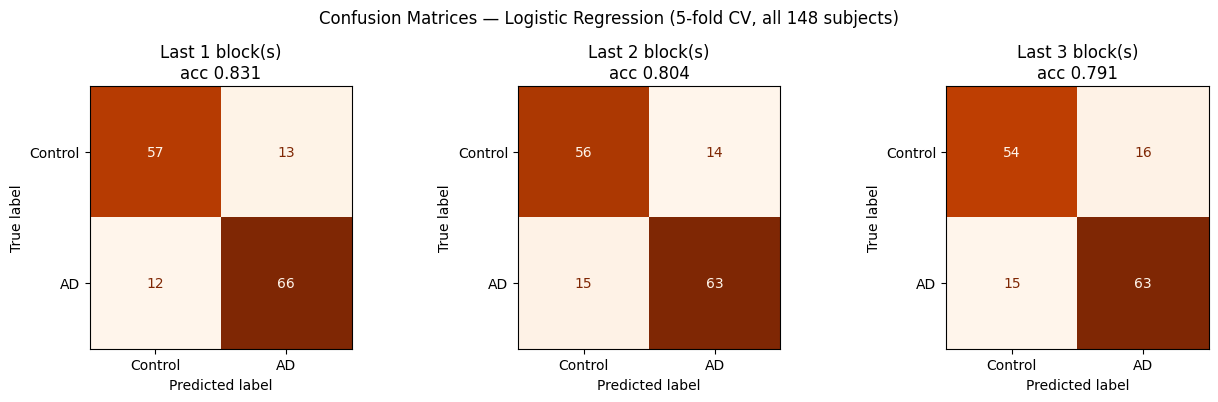

Saved lr_confusion_cv.png


In [6]:
# Confusion matrices — 5-fold CV (all 148 subjects), LR head
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for col, nf in enumerate([10, 9, 8]):
    cv = cv_results[nf]
    ConfusionMatrixDisplay(confusion_matrix(cv['y_true'], cv['lr_pred']),
                           display_labels=['Control', 'AD']).plot(ax=axes[col], colorbar=False, cmap='Oranges')
    axes[col].set_title(f'Last {11-nf} block(s)\nacc {accuracy_score(cv["y_true"], cv["lr_pred"]):.3f}')
fig.suptitle('Confusion Matrices — Logistic Regression (5-fold CV, all 148 subjects)', fontsize=12)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, 'lr_confusion_cv.png'), dpi=150); plt.show()
print('Saved lr_confusion_cv.png')

## ROC curves (5-fold CV)

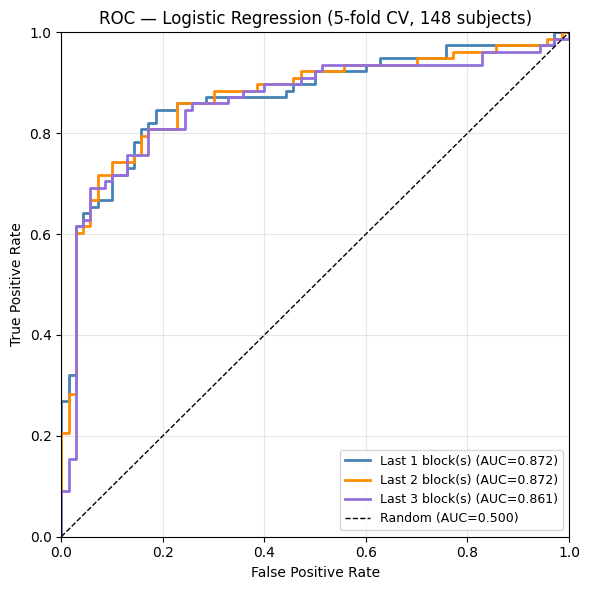

Saved lr_roc_cv.png


In [7]:
# ROC — 5-fold CV (all 148 subjects), LR head
fig, ax = plt.subplots(figsize=(6, 6))
for nf, color in zip([10, 9, 8], ['steelblue', 'darkorange', 'mediumpurple']):
    cv = cv_results[nf]
    fpr, tpr, _ = roc_curve(cv['y_true'], cv['lr_prob'])
    ax.plot(fpr, tpr, color=color, lw=2, label=f'Last {11-nf} block(s) (AUC={roc_auc_score(cv["y_true"], cv["lr_prob"]):.3f})')
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Random (AUC=0.500)')
ax.set_xlabel('False Positive Rate'); ax.set_ylabel('True Positive Rate')
ax.set_title('ROC — Logistic Regression (5-fold CV, 148 subjects)')
ax.legend(fontsize=9, loc='lower right'); ax.grid(alpha=0.3); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, 'lr_roc_cv.png'), dpi=150); plt.show()
print('Saved lr_roc_cv.png')